### Aula 1 - Modelo Palete Caixa

In [1]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

#### Dados de entrada e nomenclaturas/simbologias utilizadas 

In [2]:
comprimentos_palete = [8,50,50]
larguras_palete = [6,50,40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [3]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões do caixa: {caixa_comprimento}x{caixa_largura}")



Dimensões do palete: 8x6
Dimensões do caixa: 3x2


---
#### Pela notação do Prof, 
#### A largura do palete sempre deve ser maior comprimento: L>W
#### A largura da caixa sempre deve ser maior comprimento: l>w
#### _um = caixa deitada, _dois = caixa em pé
---

In [4]:
dimensoes_palete = [palete_comprimento, palete_largura]
L,W = sorted(dimensoes_palete, reverse=True)

print(f"Dimensões classificadas do palete: {L}x{W}")

Dimensões classificadas do palete: 8x6


In [5]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse=True) # Caixa _um = Horientação da caixa é deitada

print(f"Dimensões classificadas da caixa deitada (_um): {l_um}x{w_um}")

Dimensões classificadas da caixa deitada (_um): 3x2


In [6]:
l_dois, w_dois = sorted(dimensoes_caixa, reverse=False) # Caixa _dois = Horientação da caixa é em pé 
# l_dois, w_dois = dimensoes_caixa[::-1] # Caixa _dois = Horientação da caixa é em pé 
print(f"Dimensões classificadas da caixa em pé (_dois): {l_dois}x{w_dois}")


Dimensões classificadas da caixa em pé (_dois): 2x3


---
##### Criando uma função para plotar as caixas e o palete
---

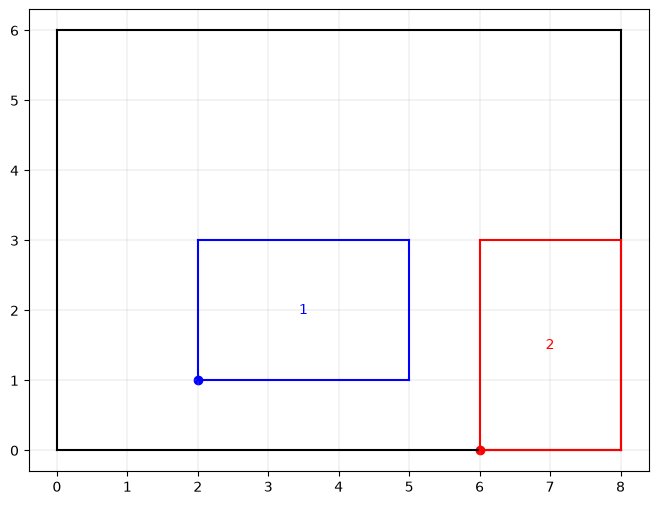

In [7]:
def plotar_caixa(bottom_left:list, #Coordenada da caixa baixo, esquerda
                 l: int, 
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0,x0+l], [y0, y0], color=color)
    plt.plot([x0,x0+l], [y0+w, y0+w], color=color)
    plt.plot([x0,x0], [y0, y0+w], color=color)
    plt.plot([x0+l,x0+l], [y0, y0+w], color=color)
    plt.text(x=x0+l/2, y=y0+w/2, s=label, color=color,
             fontsize = 10, ha="center", va="center")

def plotar_palete(L:int, W:int):
    plt.figure(figsize=(8,6))
    plt.plot([0, L], [0,0], "k-")
    plt.plot([0, 0], [0,W], "k-")
    plt.plot([0, L], [W,W], "k-")
    plt.plot([L, L], [0,W], "k-")
    plt.grid(True, linewidth=0.2)

plotar_palete(L, W)
plotar_caixa(bottom_left=[2,1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6,0], l=2, w=3, color="red", label="2")


---
#### Funções para verificar quantas caixas cabem na horizontal [f_um] (varrendo as combinações das caixas deitadas e em pé) -> soma resulta em p

#### Funções para verificar quantas caixas cabem na vertical [f_dois] (varrendo as combinações das caixas deitadas e em pé) -> soma resulta em q
---

In [8]:
f_um = lambda n_um, l_um, n_dois, l_dois: n_um*l_um + n_dois*l_dois #p <= L - w_um

f_dois = lambda n_um, w_um, n_dois, w_dois: n_um*w_um + n_dois*w_dois #q <= L - w_um

In [9]:
print(f_um(n_um=2,l_um=3, n_dois=1, l_dois=2))
print(f_dois(n_um=2,w_um=2, n_dois=1, w_dois=3))


8
7


---
#### Varrendo todas as possibilidades para posicionar as caixas na horizontal
---

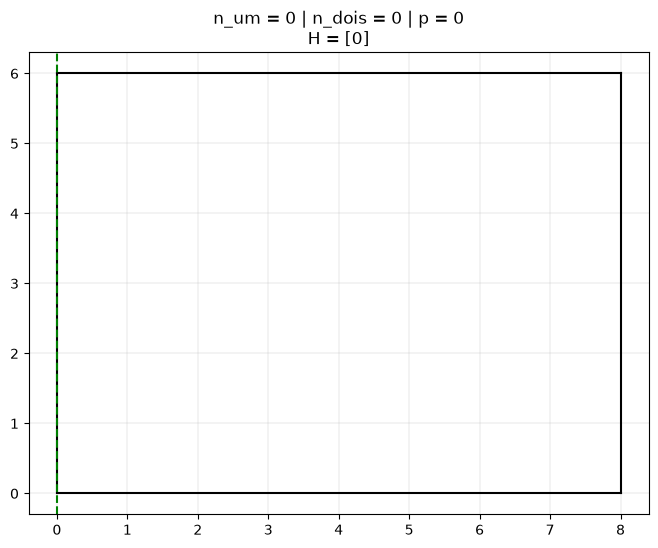

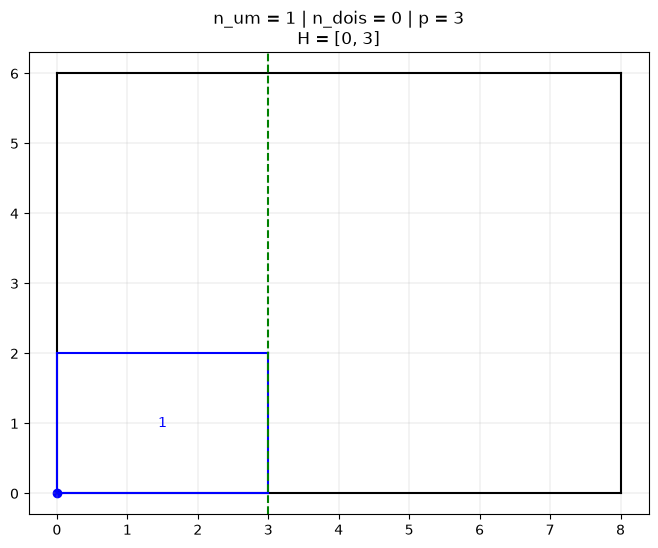

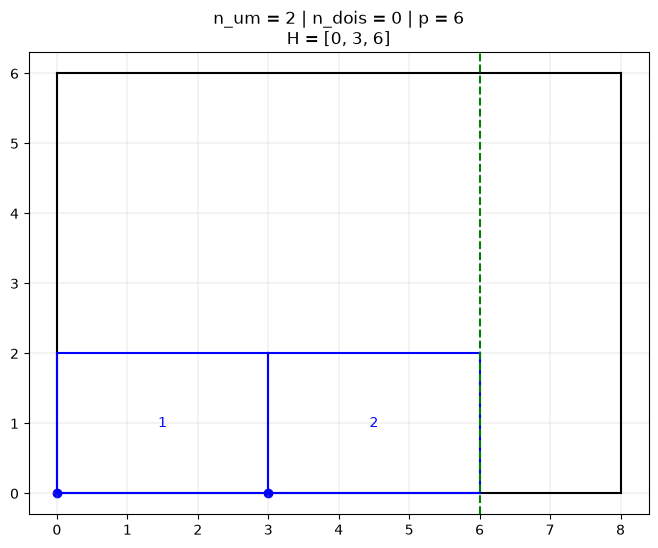

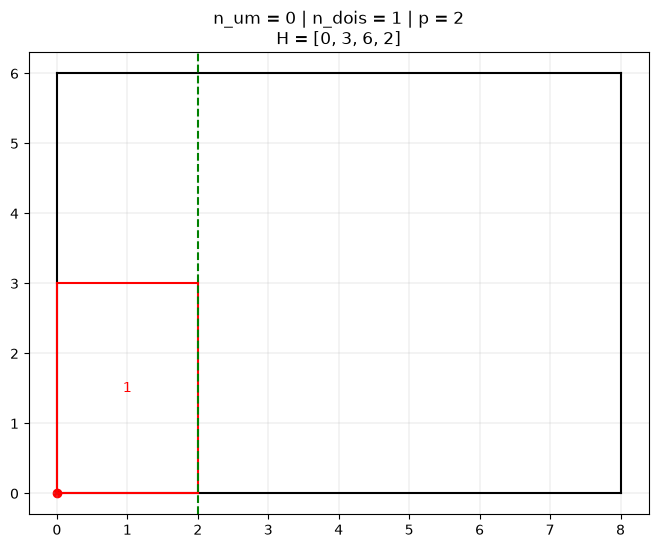

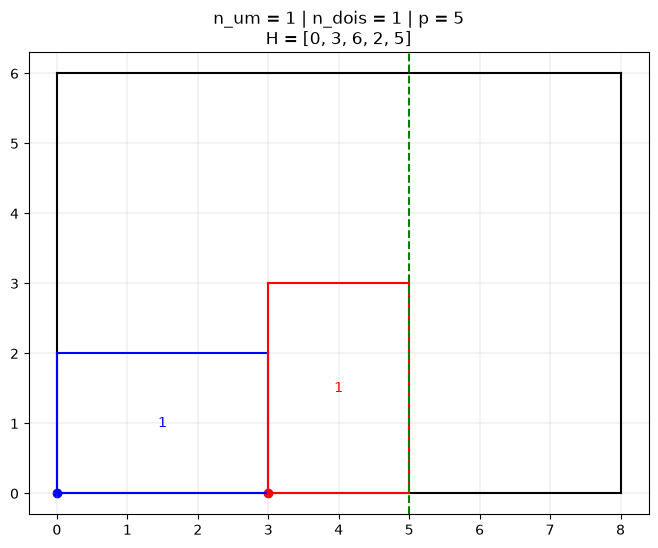

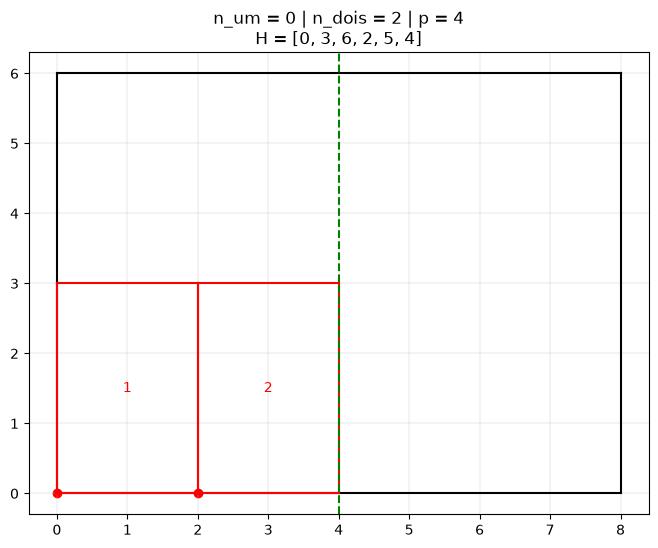

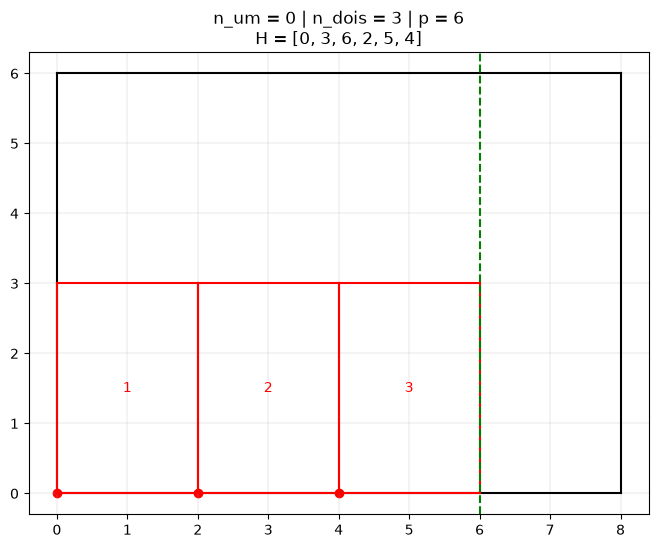

In [10]:
# Lista do H
H = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    # print(n_um, n_dois, p)
    if p<= L-w_um:
        if p not in H:
            H.append(p)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[n*l_um,0], l=l_um, w=w_um, color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um*l_um + n*l_dois,0], l=l_dois, w=w_dois, color="red", label=n+1)
            
        plt.axvline(x=p, color="green", linestyle="--")
        plt.title(f"{n_um = } | {n_dois = } | {p = }\n{H = }")


In [11]:
H

[0, 3, 6, 2, 5, 4]

---
#### Varrendo todas as possibilidades para posicionar as caixas na Vertical
---

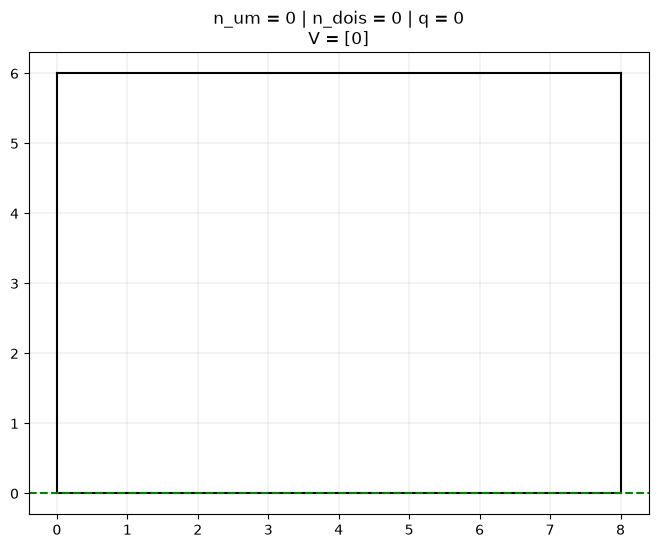

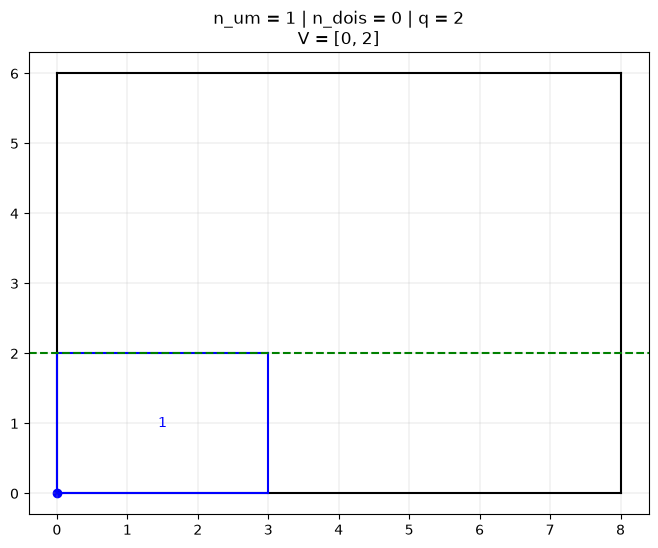

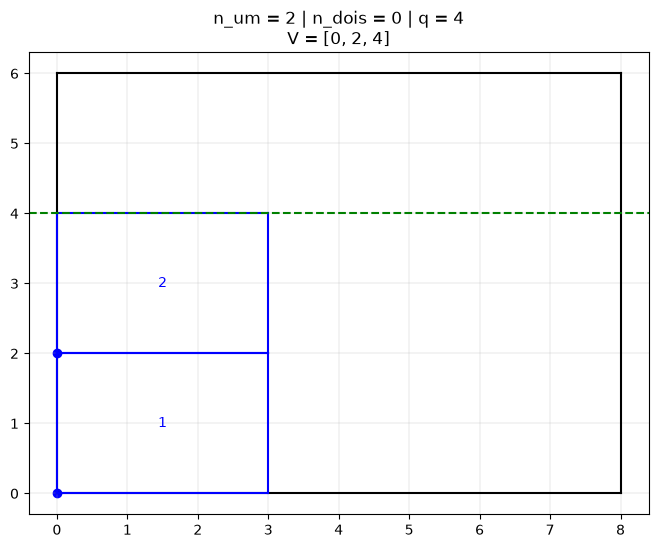

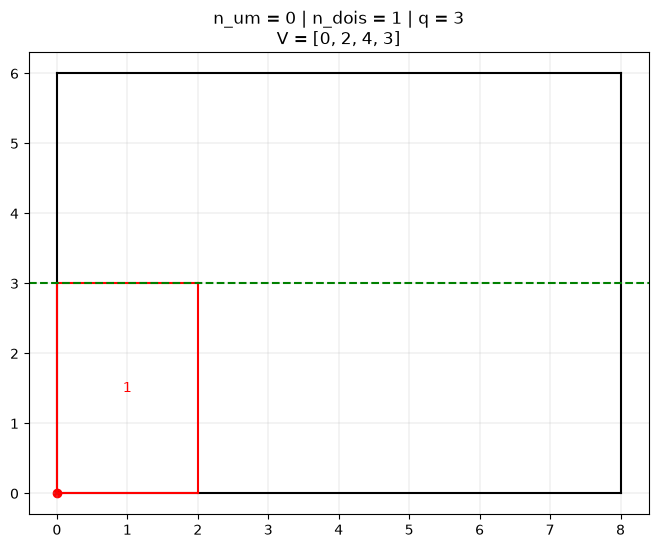

In [12]:
# Lista do H
V = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    # print(n_um, n_dois, q)
    if q <= W-w_um:
        if q not in V:
            V.append(q)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n*w_um], l=l_um, w=w_um, color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0,n_um*w_um + n*w_dois], l=l_dois, w=w_dois, color="red", label=n+1)
            
        plt.axhline(y=q, color="green", linestyle="--")
        plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }")


---

In [13]:
# Organizando 

H = sorted(H)
V = sorted(V)

print(H)
print(V)

[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]


In [14]:
lista_rs = list(product(H,V))
display(lista_rs)

[(0, 0),
 (0, 2),
 (0, 3),
 (0, 4),
 (2, 0),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 0),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 0),
 (4, 2),
 (4, 3),
 (4, 4),
 (5, 0),
 (5, 2),
 (5, 3),
 (5, 4),
 (6, 0),
 (6, 2),
 (6, 3),
 (6, 4)]

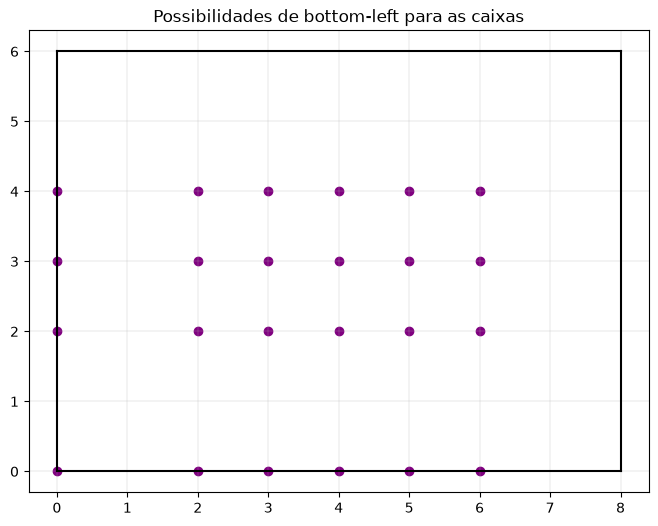

In [15]:
if indice == 0:
    plotar_palete(L, W)
    for r, s in lista_rs:
        plt.scatter(x=r, y=s, color="purple")

    plt.title("Possibilidades de bottom-left para as caixas")
    plt.show()

---
#### Filtrando os pontos 

In [16]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [17]:
# Caixa deitada e caixa em Pé
i = 1
print(ls[i-1], ws[i-1])

3 2


---
#### Lista de tuplas

#### i, p, q :
####  i = 1 ou 2 = deitada ou em pé
####  p, q = par ordenado das possibilidade do bottom left

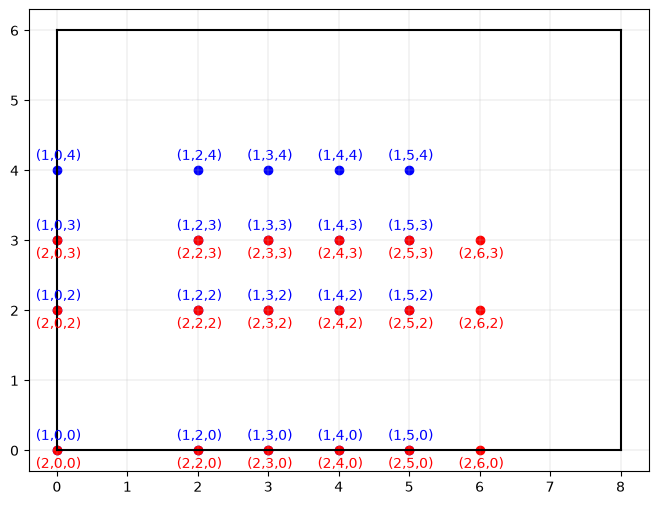

In [18]:
lista_variaveis = []

plotar_palete(L,W)

for (p, q), i in product(lista_rs, [1,2]):
    # print(i,p,q)
    if p+ls[i-1] <= L and q+ws[i-1] <= W: # Checa se cabe ou não no palete
        lista_variaveis.append((i,p,q))

        if indice == 0:
            cor = "blue" if i ==1 else "red"
            plt.scatter(x=p, y=q, color = cor) # plot a bottom-left

            if i==1:
                plt.text(x=p-0.3, y=q+0.15, s=f"({i},{p},{q})", color=cor, fontsize=10)
            else:
                plt.text(x=p-0.3, y=q-0.25, s=f"({i},{p},{q})", color=cor, fontsize=10)


# lista_variaveis

In [19]:
len(lista_variaveis)

38

---
#### Criando a Função Objetivo para ser maximização

In [20]:
prob = plp.LpProblem(name="Palete-Caixa",
                     sense=plp.LpMaximize) #Maximização

display(prob)

Palete-Caixa:
MAXIMIZE
None
VARIABLES

In [21]:
dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis,
                                      lowBound=0, upBound=1,
                                      cat=plp.LpBinary)

display(dict_variaveis)

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 2): C_(1,_0,_2),
 (2, 0, 2): C_(2,_0,_2),
 (1, 0, 3): C_(1,_0,_3),
 (2, 0, 3): C_(2,_0,_3),
 (1, 0, 4): C_(1,_0,_4),
 (1, 2, 0): C_(1,_2,_0),
 (2, 2, 0): C_(2,_2,_0),
 (1, 2, 2): C_(1,_2,_2),
 (2, 2, 2): C_(2,_2,_2),
 (1, 2, 3): C_(1,_2,_3),
 (2, 2, 3): C_(2,_2,_3),
 (1, 2, 4): C_(1,_2,_4),
 (1, 3, 0): C_(1,_3,_0),
 (2, 3, 0): C_(2,_3,_0),
 (1, 3, 2): C_(1,_3,_2),
 (2, 3, 2): C_(2,_3,_2),
 (1, 3, 3): C_(1,_3,_3),
 (2, 3, 3): C_(2,_3,_3),
 (1, 3, 4): C_(1,_3,_4),
 (1, 4, 0): C_(1,_4,_0),
 (2, 4, 0): C_(2,_4,_0),
 (1, 4, 2): C_(1,_4,_2),
 (2, 4, 2): C_(2,_4,_2),
 (1, 4, 3): C_(1,_4,_3),
 (2, 4, 3): C_(2,_4,_3),
 (1, 4, 4): C_(1,_4,_4),
 (1, 5, 0): C_(1,_5,_0),
 (2, 5, 0): C_(2,_5,_0),
 (1, 5, 2): C_(1,_5,_2),
 (2, 5, 2): C_(2,_5,_2),
 (1, 5, 3): C_(1,_5,_3),
 (2, 5, 3): C_(2,_5,_3),
 (1, 5, 4): C_(1,_5,_4),
 (2, 6, 0): C_(2,_6,_0),
 (2, 6, 2): C_(2,_6,_2),
 (2, 6, 3): C_(2,_6,_3)}

In [22]:
dict_variaveis.values()


dict_values([C_(1,_0,_0), C_(2,_0,_0), C_(1,_0,_2), C_(2,_0,_2), C_(1,_0,_3), C_(2,_0,_3), C_(1,_0,_4), C_(1,_2,_0), C_(2,_2,_0), C_(1,_2,_2), C_(2,_2,_2), C_(1,_2,_3), C_(2,_2,_3), C_(1,_2,_4), C_(1,_3,_0), C_(2,_3,_0), C_(1,_3,_2), C_(2,_3,_2), C_(1,_3,_3), C_(2,_3,_3), C_(1,_3,_4), C_(1,_4,_0), C_(2,_4,_0), C_(1,_4,_2), C_(2,_4,_2), C_(1,_4,_3), C_(2,_4,_3), C_(1,_4,_4), C_(1,_5,_0), C_(2,_5,_0), C_(1,_5,_2), C_(2,_5,_2), C_(1,_5,_3), C_(2,_5,_3), C_(1,_5,_4), C_(2,_6,_0), C_(2,_6,_2), C_(2,_6,_3)])

In [23]:
sum(dict_variaveis.values())


1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0

In [24]:
# Adicionando no Prob

prob += sum(dict_variaveis.values())
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
VARIABLES
0 <= C_(1,_0,_0) <= 1 Integer
0 <= C_(1,_0,_2) <= 1 Integer
0 <= C_(1,_0,_3) <= 1 Integer
0 <= C_(1,_0,_4) <= 1 Integer
0 <= C_(1,_2,_0) <= 1 Integer
0 <= C_(1,_2,_2) <= 1 Integer
0 <= C_(1,_2,_3) <= 1 Integer
0 <= C_(1,_2,_4) <= 1 Integer
0 <= C_(1,_3,_0) <= 1 Integer
0 <= C_(1,_3,_2) <= 1 Integer
0 <= C_(1,_3,_3) <= 1 Integer
0 <= C_(1,_3,_4) <= 1 Integ

---
---
---
### Aula 2 - 20/09/2026 - Iniciar as restrições

In [25]:
print(f"Qtd variáveis: {prob.numVariables()}")

Qtd variáveis: 38


In [26]:
print(f"Qtd restrições: {prob.numConstraints()}")

Qtd restrições: 0


---
#### Restrição do Tipo 1: Verificar se os pontos rs está dentro ou não da caixa

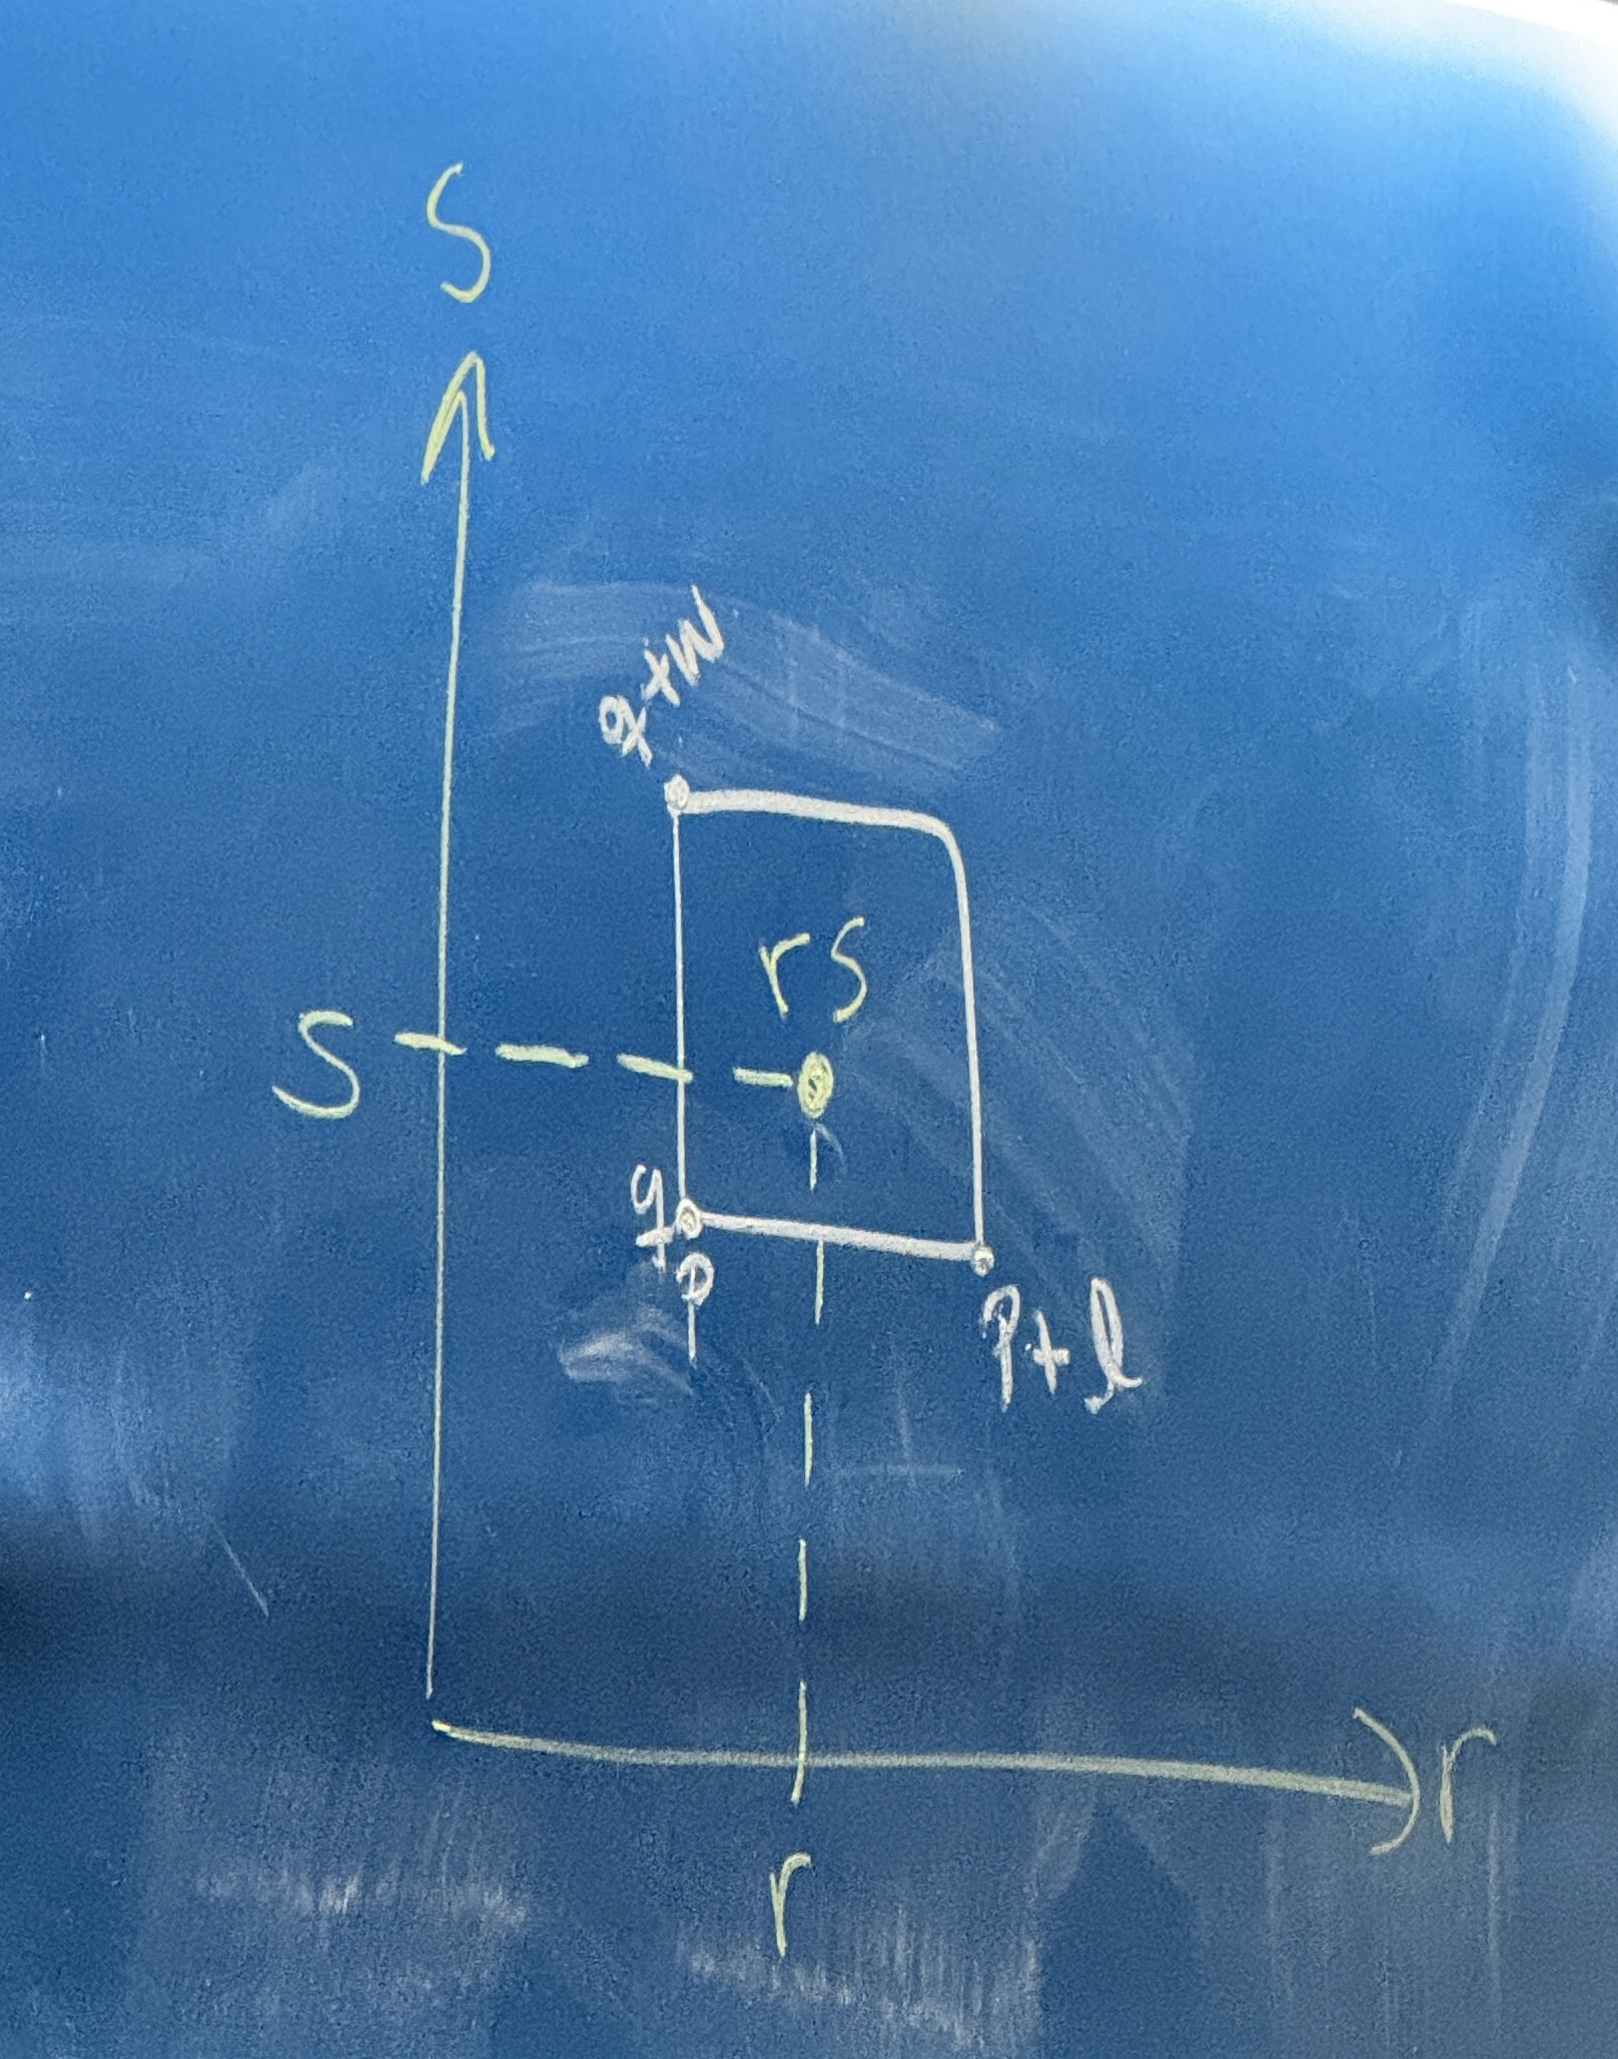

In [27]:
def ponto_dentro_caixa(ponto_rs: tuple, #Ponto_rs para ser testado
                       ponto_pq: tuple, #Bottom left da caixa a ser testada
                       l:int, w:int) -> bool: # Caixa em pé ou deitada 
    r,s = ponto_rs
    p, q = ponto_pq
    return p <= r < p+l and q<= s < q+w 

In [28]:
ponto_dentro_caixa((6,2),
                   (6,0),
                   l=ls[0], w=ws[0])

False

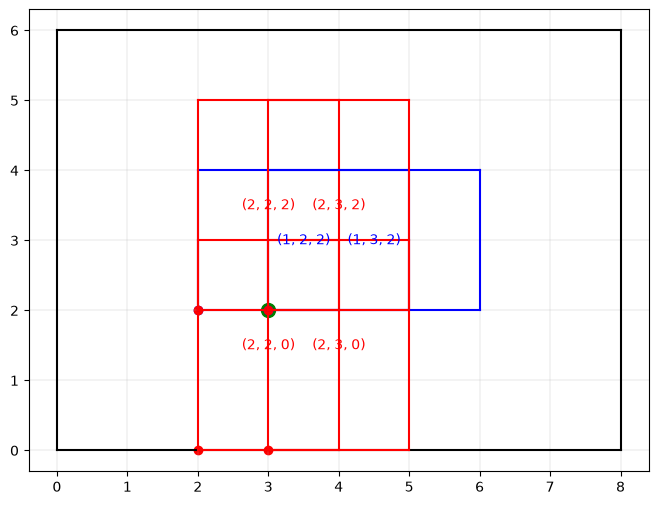

In [29]:
plotar_palete(L, W)
r, s = lista_rs[9]
plt.scatter(x=r, y=s, color="green", s=100)

caixa_sobrepostas = []
for i,p,q in lista_variaveis:
    if ponto_dentro_caixa((r,s),
                          (p,q),
                          l=ls[i-1], w=ws[i-1]):
        plotar_caixa((p,q), ls[i-1], ws[i-1],
                     color="blue" if i == 1 else "red",
                     label=f"{i,p,q}")

In [30]:
# plotar_palete(L, W)
r, s = lista_rs[9]
# plt.scatter(x=r, y=s color="green", s=100)

n=0
for r,s in lista_rs:
    caixa_sobrepostas = []

    for i,p,q in lista_variaveis:
        if ponto_dentro_caixa((r,s),
                            (p,q),
                            l=ls[i-1], w=ws[i-1]):
            # caixa_sobrepostas.append((i,p,q))
            caixa_sobrepostas.append(dict_variaveis[(i,p,q)])
    # print(sum(caixa_sobrepostas))
    prob += sum(caixa_sobrepostas)<=1, f"Restricao 1.{n}" # Só por causa do <= o pulp entende que é uma restricao
    n += 1
    




In [31]:
print(prob.numVariables())

38


In [32]:
print(prob.numConstraints())

24


---
#### Restrição do tipo 2 = Pela área máxima 

In [33]:
qtd_maxima_caixas = (L*W) // (l_um*w_um)
qtd_maxima_caixas

8

In [34]:
prob += sum(dict_variaveis.values()) <= qtd_maxima_caixas, "Restricao_2.0"
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
SUBJECT TO
Restricao_1.0: C_(1,_0,_0) + C_(2,_0,_0) <= 1

Restricao_1.1: C_(1,_0,_2) + C_(2,_0,_0) + C_(2,_0,_2) <= 1

Restricao_1.2: C_(1,_0,_2) + C_(1,_0,_3) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.3: C_(1,_0,_3) + C_(1,_0,_4) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.4: C_(1,_0,_0) + C_(1,_2,_0) + C_(2,_2,_0) <= 1

Restricao_1.5: C_(1,_0,_2) + C_(1,_2,

In [35]:
prob.numConstraints()

25

In [36]:
# solver = plp.getSolver("COIN_CMD", timeLimit=None)
solver = plp.getSolver("HiGHS_CMD", timeLimit=None)
solver

In [37]:
prob.solve(solver)

Running HiGHS 1.9.0 (git hash: n/a): Copyright (c) 2024 HiGHS under MIT licence terms
Number of BV entries in BOUNDS section is 38
MIP  fcfce093f3564560b582a6ecbc456725-pulp has 25 rows; 38 cols; 186 nonzeros; 38 integer variables
Coefficient ranges:
  Matrix [1e+00, 1e+00]
  Cost   [1e+00, 1e+00]
  Bound  [1e+00, 1e+00]
  RHS    [1e+00, 8e+00]
Presolving model
25 rows, 38 cols, 186 nonzeros  0s
25 rows, 22 cols, 94 nonzeros  0s
Objective function is integral with scale 1

Solving MIP model with:
   25 rows
   22 cols (22 binary, 0 integer, 0 implied int., 0 continuous)
   94 nonzeros

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic; L => Sub-MIP;
     P => Empty MIP; R => Randomized rounding; S => Solve LP; T => Evaluate node; U => Unbounded;
     z => Trivial zero; l => Trivial lower; u => Trivial upper; p => Trivial point

        Nodes      |    B&B Tree     |            Objective Bounds              |  Dynamic Constraints |       Work      
Src  P

1

In [38]:
print(prob.variables()[0].varValue)
print(prob.variables()[1].varValue)
print(prob.objective.value())

0.0
0.0
8.0


In [39]:
# Conversão do dict_variavies -> chave vira valor, valor vira chave

dict_traducao = dict(zip(dict_variaveis.values(),
                         dict_variaveis.keys()))

display(dict_traducao)

{C_(1,_0,_0): (1, 0, 0),
 C_(2,_0,_0): (2, 0, 0),
 C_(1,_0,_2): (1, 0, 2),
 C_(2,_0,_2): (2, 0, 2),
 C_(1,_0,_3): (1, 0, 3),
 C_(2,_0,_3): (2, 0, 3),
 C_(1,_0,_4): (1, 0, 4),
 C_(1,_2,_0): (1, 2, 0),
 C_(2,_2,_0): (2, 2, 0),
 C_(1,_2,_2): (1, 2, 2),
 C_(2,_2,_2): (2, 2, 2),
 C_(1,_2,_3): (1, 2, 3),
 C_(2,_2,_3): (2, 2, 3),
 C_(1,_2,_4): (1, 2, 4),
 C_(1,_3,_0): (1, 3, 0),
 C_(2,_3,_0): (2, 3, 0),
 C_(1,_3,_2): (1, 3, 2),
 C_(2,_3,_2): (2, 3, 2),
 C_(1,_3,_3): (1, 3, 3),
 C_(2,_3,_3): (2, 3, 3),
 C_(1,_3,_4): (1, 3, 4),
 C_(1,_4,_0): (1, 4, 0),
 C_(2,_4,_0): (2, 4, 0),
 C_(1,_4,_2): (1, 4, 2),
 C_(2,_4,_2): (2, 4, 2),
 C_(1,_4,_3): (1, 4, 3),
 C_(2,_4,_3): (2, 4, 3),
 C_(1,_4,_4): (1, 4, 4),
 C_(1,_5,_0): (1, 5, 0),
 C_(2,_5,_0): (2, 5, 0),
 C_(1,_5,_2): (1, 5, 2),
 C_(2,_5,_2): (2, 5, 2),
 C_(1,_5,_3): (1, 5, 3),
 C_(2,_5,_3): (2, 5, 3),
 C_(1,_5,_4): (1, 5, 4),
 C_(2,_6,_0): (2, 6, 0),
 C_(2,_6,_2): (2, 6, 2),
 C_(2,_6,_3): (2, 6, 3)}

In [40]:
# Checar qual das variaveis são maior do que 1
variaveis_organizadas = []

for variavel in prob.variables():
    # print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)

display(variaveis_organizadas)

[(2, 0, 0),
 (2, 0, 3),
 (2, 2, 0),
 (2, 2, 3),
 (2, 4, 0),
 (2, 4, 3),
 (2, 6, 0),
 (2, 6, 3)]

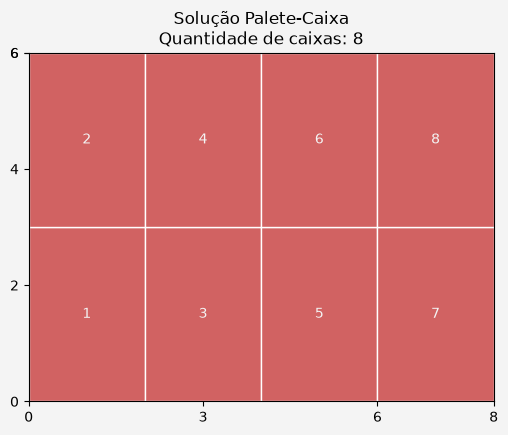

In [41]:
fig, ax = plt.subplots(figsize=(6, 6))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=10,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=12)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=10)
ax.yaxis.set_tick_params(labelsize=10)

In [42]:
print(plp.listSolvers(onlyAvailable=True))

['GLPK_CMD', 'PULP_CBC_CMD', 'COIN_CMD', 'HiGHS_CMD']


---

In [43]:
# Fixa a lista e não muda na memória

from copy import deepcopy

solucoes = [deepcopy(variaveis_organizadas)]
solucoes

[[(2, 0, 0),
  (2, 0, 3),
  (2, 2, 0),
  (2, 2, 3),
  (2, 4, 0),
  (2, 4, 3),
  (2, 6, 0),
  (2, 6, 3)]]

---
#### Adicionando uma restrição para encontrar outra solução

In [44]:
from random import random, seed
seed(42)

n = 0 
for variavel in prob.variables():
    if variavel.varValue > 0:
        if random() > 0.2:
            continue

        # print(variavel)
        prob += variavel == 0, f"Restricao_3.{n}"
        n+=1
        
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
SUBJECT TO
Restricao_1.0: C_(1,_0,_0) + C_(2,_0,_0) <= 1

Restricao_1.1: C_(1,_0,_2) + C_(2,_0,_0) + C_(2,_0,_2) <= 1

Restricao_1.2: C_(1,_0,_2) + C_(1,_0,_3) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.3: C_(1,_0,_3) + C_(1,_0,_4) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.4: C_(1,_0,_0) + C_(1,_2,_0) + C_(2,_2,_0) <= 1

Restricao_1.5: C_(1,_0,_2) + C_(1,_2,

In [45]:
print(prob.numConstraints())
print(prob.numVariables())

27
38


---
#### Rodando novamente

In [46]:
solver = plp.getSolver("COIN_CMD", timeLimit=None)

In [47]:
prob.solve(solver)

Welcome to the CBC MILP Solver 
Version: 2.10.13 
Build Date: Mar 11 2026 

command line - cbc /var/folders/jg/xx4mf49n7vjc59g_17rlyp4c0000gn/T/7461d32c037343e3b66d087b2b2a21c2-pulp.mps -max -timeMode elapsed -solve -printingOptions all -solution /var/folders/jg/xx4mf49n7vjc59g_17rlyp4c0000gn/T/7461d32c037343e3b66d087b2b2a21c2-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 32 COLUMNS
At line 335 RHS
At line 363 BOUNDS
At line 402 ENDATA
Problem MODEL has 27 rows, 38 columns and 188 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 8 - 0.00 seconds
Cgl0002I 2 variables fixed
Cgl0004I processed model has 25 rows, 35 columns (35 integer (35 of which binary)) and 175 elements
Cutoff increment increased from 1e-05 to 0.9999
Cbc0038I Initial state - 0 integers unsatisfied sum - 0
Cbc0038I Solution found of 8
Cbc0038I Before mini branch and bound, 35 integers at bound fixed and 0 contin

1

In [48]:
variaveis_organizadas = []
for variavel in prob.variables():
    # print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 0, 0),
 (1, 0, 2),
 (1, 0, 4),
 (1, 5, 0),
 (1, 5, 2),
 (1, 5, 4),
 (2, 3, 0),
 (2, 3, 3)]

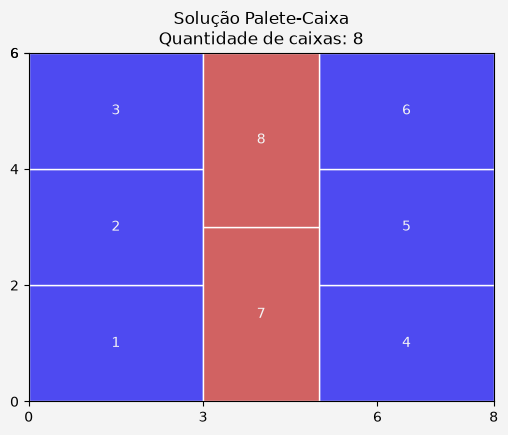

In [49]:
fig, ax = plt.subplots(figsize=(6, 6))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=10,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=12)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=10)
ax.yaxis.set_tick_params(labelsize=10)